# XGBoost Hyperparameter Search

## 1. Objective

The objective of this notebook is to tune XGBoost for predicting restaurant `weighted_rating`, using only the training data and 5-fold cross-validation.

The best settings, their validation scores and a refit model are meant to feed the ensemble notebook.

## 2. Problem Statement

This project predicts the weighted rating of a restaurant from the prepared restaurant features (cuisine, location, menu, pricing and geography).

**Target Variable:** `weighted_rating`

**Problem Type:** Supervised Machine Learning - Regression

## 3. Evaluation Metrics

The models are evaluated with:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE), the main metric for choosing settings
- R-squared (R²)

Every score is the mean and standard deviation over the same 5 folds (`KFold`, `shuffle=True`, `random_state=42`). The standard deviation is the population standard deviation (`ddof=0`) of the 5 fold scores, the same convention the search already used.

## 4. Approach

The search is a simple Bayesian search with 15 trials. Each trial is scored by 5-fold cross-validation on the training rows, and the mean RMSE is the only feedback the search gets.

1. The first 3 trials are random.
2. A Gaussian process is fitted to every (settings, score) pair so far. For a new setting it predicts a score and how unsure it is.
3. A large pool of candidates is scored with expected improvement and the best one is tried next. The exploration factor is `XI = 0.002`.

After the search, the best settings are run through 5-fold cross-validation once more to record MAE, RMSE and R² for every fold. Then the model is refit on all training rows.

How to run it: one trial is 5 cross-validation fits, so a cell can take a few minutes. Any trial cell can be interrupted, and finished trials are kept. A 90-minute safety limit stops the search if the machine is slow.

## 5. Expected Outcome

A set of best settings, a validation table with mean ± std for MAE, RMSE and R², and a model refit on the full training split.

## 6. How the test set was used

The test set is not used in this notebook. It is not loaded, and it plays no part in any choice here. All tuning and all choices use only the training data with 5-fold cross-validation. The test set is used once, at the end of the project, for the single final chosen model or ensemble, in the last cell of the ensemble notebook.

## 1. Install the requirements (run this once)

This installs the libraries these notebooks need. You can skip it if they are already installed.

In [1]:
%pip install -q --upgrade xgboost lightgbm scikit-learn scipy pandas numpy matplotlib
print("Requirements installed - continue with the next cell.")

Note: you may need to restart the kernel to use updated packages.
Requirements installed - continue with the next cell.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports and configuration

Paths follow `Baseline_Model_Training`: prepared data is read from `data/processed`, so no preprocessing is repeated here. The seed, the number of folds and the search budget are set in this cell.

In [2]:
from xgboost import XGBRegressor

import os
import time
import warnings
import pickle
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel

from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 190)

# ================================ CONFIG ================================
DATA_DIR = "data/processed"     # prepared datasets from the EDA notebook
RANDOM_STATE = 42
CV_FOLDS = 5

N_TRIALS = 15                   # total configurations to try
N_WARMUP = 3                    # first trials are random, the rest are chosen by the model

EXPLORE_XI = 0.002              # exploration factor in expected improvement
N_POOL = 4000                   # candidates drawn over the whole space
N_LOCAL = 3000                  # candidates drawn around the current best
LOCAL_SCALE = 0.20              # how wide that neighbourhood is
KERNEL_RESTARTS = 2
TIME_LIMIT_MIN = 90             # safety stop, so a run always ends
# ========================================================================

print("Data folder :", DATA_DIR)
print(f"Budget      : {N_TRIALS} trials x {CV_FOLDS} folds")
print(f"Search      : Gaussian process + expected improvement (xi = {EXPLORE_XI})")

Data folder : data/processed
Budget      : 15 trials x 5 folds
Search      : Gaussian process + expected improvement (xi = 0.002)


## 3. Load the training data

Only the training features and the target are loaded. The test files are not read in this notebook.

**Evaluation split (updated):** the original training data is split once into 80% development (`X_train`, `y_train`) and 20% validation (`X_val`, `y_val`, seed 42). The search and all 5-fold CV use the development data only. The validation rows are scored once for the selected settings, and the final model is refit on 100% of the original training data (`X_full`, `y_full`). The test set is never loaded.

In [3]:
DATA_FILES = ["X_train_processed.csv", "y_train.csv"]
missing = [f for f in DATA_FILES if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in '{DATA_DIR}'. Run the EDA / preprocessing notebook first, "
        "or set DATA_DIR to the folder that holds these prepared files."
    )

X_train = pd.read_csv(os.path.join(DATA_DIR, "X_train_processed.csv"))
y_train = pd.read_csv(os.path.join(DATA_DIR, "y_train.csv")).squeeze("columns")

print(f"Train      {X_train.shape}")
print("Missing values (train):", int(X_train.isna().sum().sum()))
print(f"Target      mean {y_train.mean():.4f} | std {y_train.std():.4f}")

# ---- Evaluation split: 80% development / 20% validation (hold-out) ----
# Tuning and 5-fold CV use ONLY the development rows. X_full / y_full (100% of the original
# training data) are used only for the final refit. The test set is never loaded.
from sklearn.model_selection import train_test_split
VAL_SIZE = 0.20
X_full, y_full = X_train.copy(), y_train.copy()
X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=VAL_SIZE, random_state=RANDOM_STATE, shuffle=True)
X_train, X_val = X_train.reset_index(drop=True), X_val.reset_index(drop=True)
y_train, y_val = y_train.reset_index(drop=True), y_val.reset_index(drop=True)
print(f"Development (tuning + CV): {X_train.shape} | Validation (held out): {X_val.shape} | Full train (final refit only): {X_full.shape}")


Train      (53574, 263)
Missing values (train): 0
Target      mean 3.9372 | std 0.1699
Development (tuning + CV): (42859, 263) | Validation (held out): (10715, 263) | Full train (final refit only): (53574, 263)


## 4. Search space

Each dial is mapped to a number between 0 and 1 because the Gaussian process needs a common scale. The decoded values are always valid XGBoost settings.

| Dial | Range | Type |
|---|---|---|
| `n_estimators` | 300 to 1000 | one of eight choices |
| `learning_rate` | 0.02 to 0.15 | continuous, log scale |
| `max_depth` | 3 to 9 | integer |
| `min_child_weight` | 1 to 20 | continuous, log scale |
| `subsample` | 0.6 to 1.0 | continuous |
| `colsample_bytree` | 0.5 to 1.0 | continuous |
| `reg_lambda` | 0.5 to 20 | continuous, log scale |

In [4]:
class SearchSpace:
    """Turns a vector of numbers in [0, 1] into real hyperparameter values."""

    def __init__(self, dims):
        self.dims = dims

    @property
    def names(self):
        return [name for name, _, _ in self.dims]

    @property
    def d(self):
        return len(self.dims)

    def decode(self, u):
        params = {}
        for (name, kind, spec), value in zip(self.dims, np.clip(u, 0.0, 1.0)):
            if kind == "choice":
                params[name] = spec[int(round(value * (len(spec) - 1)))]
            elif kind == "int":
                lo, hi = spec
                params[name] = int(round(lo + value * (hi - lo)))
            elif kind == "log":
                lo, hi = spec
                params[name] = float(10 ** (np.log10(lo) + value * (np.log10(hi) - np.log10(lo))))
            elif kind == "linear":
                lo, hi = spec
                params[name] = float(lo + value * (hi - lo))
            else:
                raise ValueError(kind)
        return params

    def encode(self, params):
        u = []
        for name, kind, spec in self.dims:
            value = params[name]
            if kind == "choice":
                u.append(spec.index(value) / (len(spec) - 1))
            elif kind == "int":
                lo, hi = spec
                u.append((value - lo) / (hi - lo))
            elif kind == "log":
                lo, hi = spec
                u.append((np.log10(value) - np.log10(lo)) / (np.log10(hi) - np.log10(lo)))
            elif kind == "linear":
                lo, hi = spec
                u.append((value - lo) / (hi - lo))
        return np.array(u, dtype=float)

    def signature(self, params):
        return tuple(sorted(params.items()))


SPACE = SearchSpace([
    ("n_estimators", "choice", [300, 400, 500, 600, 700, 800, 900, 1000]),
    ("learning_rate", "log", (0.02, 0.15)),
    ("max_depth", "int", (3, 9)),
    ("min_child_weight", "log", (1.0, 20.0)),
    ("subsample", "linear", (0.6, 1.0)),
    ("colsample_bytree", "linear", (0.5, 1.0)),
    ("reg_lambda", "log", (0.5, 20.0)),
])

print('Dials:', SPACE.d, SPACE.names)

Dials: 7 ['n_estimators', 'learning_rate', 'max_depth', 'min_child_weight', 'subsample', 'colsample_bytree', 'reg_lambda']


## 5. The score

One function scores one configuration: 5-fold cross-validation on the training rows, the same folds every time, mean RMSE returned. That number is the only feedback the search gets. A configuration that fails is scored at 1.0 instead of crashing the run, and a repeated configuration is answered from the cache.

In [5]:
def make_model(**params):
    return XGBRegressor(objective="reg:squarederror", tree_method="hist",
                        random_state=RANDOM_STATE, n_jobs=-1, verbosity=0, **params)

cv_folds = list(KFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_train))
CACHE = {}


def cv_score(params):
    """Mean 5-fold CV RMSE, its spread across folds, and the time it took."""
    key = tuple(sorted(params.items()))
    if key in CACHE:
        rmse, std, _ = CACHE[key]
        return rmse, std, 0.0

    t0 = time.time()
    try:
        scores = []
        for tr_idx, va_idx in cv_folds:
            model = make_model(**params)
            model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
            pred = model.predict(X_train.iloc[va_idx])
            scores.append(float(np.sqrt(mean_squared_error(y_train.iloc[va_idx], pred))))
        out = (float(np.mean(scores)), float(np.std(scores)), time.time() - t0)
    except Exception as exc:
        print(f"    fit failed ({type(exc).__name__}) - scored as 1.0")
        out = (1.0, 0.0, time.time() - t0)

    CACHE[key] = out
    return out


def fresh_params(rng, tried):
    """A random configuration the search has not tried yet."""
    for _ in range(1000):
        params = SPACE.decode(rng.uniform(0, 1, SPACE.d))
        if SPACE.signature(params) not in tried:
            return params
    return SPACE.decode(rng.uniform(0, 1, SPACE.d))


CHECKPOINT_PATH = os.path.join("artifacts", "xgboost_search_checkpoint.pkl")
SEARCH_CONFIG = {
    "n_trials": N_TRIALS,
    "n_warmup": N_WARMUP,
    "cv_folds": CV_FOLDS,
    "random_state": RANDOM_STATE,
    "val_size": VAL_SIZE,
    "n_dev_rows": len(X_train),
    "space": SPACE.dims,
}

STATE = {"history": [], "tried": set(), "best_params": None,
         "best_rmse": float("inf"), "rng": np.random.RandomState(RANDOM_STATE + 1),
         "start": None}


def save_checkpoint():
    """Persist completed trials and RNG state for restart-safe search."""
    os.makedirs(os.path.dirname(CHECKPOINT_PATH), exist_ok=True)
    payload = {
        "config": SEARCH_CONFIG,
        "history": STATE["history"],
        "tried": list(STATE["tried"]),
        "best_params": STATE["best_params"],
        "best_rmse": STATE["best_rmse"],
        "rng_state": STATE["rng"].get_state(),
    }
    fd, temp_path = tempfile.mkstemp(
        prefix="xgboost_checkpoint_", suffix=".tmp",
        dir=os.path.dirname(CHECKPOINT_PATH)
    )
    try:
        with os.fdopen(fd, "wb") as f:
            pickle.dump(payload, f, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(temp_path, CHECKPOINT_PATH)
    finally:
        if os.path.exists(temp_path):
            os.remove(temp_path)


def load_checkpoint():
    """Restore a compatible checkpoint; otherwise begin a clean search."""
    if not os.path.exists(CHECKPOINT_PATH):
        print("No search checkpoint found; starting a new search.")
        return
    with open(CHECKPOINT_PATH, "rb") as f:
        payload = pickle.load(f)
    if payload.get("config") != SEARCH_CONFIG:
        raise ValueError(
            "The saved XGBoost checkpoint uses a different search configuration. "
            "Move/delete artifacts/xgboost_search_checkpoint.pkl to start a fresh search."
        )
    STATE["history"] = payload["history"]
    STATE["tried"] = {tuple(x) for x in payload["tried"]}
    STATE["best_params"] = payload["best_params"]
    STATE["best_rmse"] = payload["best_rmse"]
    STATE["rng"].set_state(payload["rng_state"])
    print(f"Resumed checkpoint: {len(STATE['history'])}/{N_TRIALS} trials already complete.")


load_checkpoint()
print("Folds ready:", len(cv_folds))

No search checkpoint found; starting a new search.
Folds ready: 5


## 6. The Bayesian search

`propose_next()` is the whole method, and `run_trials(n)` runs at most `n` new trials. Each completed trial is saved to `artifacts/xgboost_search_checkpoint.pkl`, so an interrupted search can resume in a fresh kernel.

In [6]:
def expected_improvement(mu, sd, best, xi=EXPLORE_XI):
    """How much better than the current best a candidate is expected to be."""
    sd = np.maximum(sd, 1e-9)
    z = (best - mu - xi) / sd
    return (best - mu - xi) * norm.cdf(z) + sd * norm.pdf(z)


def fit_gp(history):
    X_obs = np.array([SPACE.encode(h) for h in history])
    y_obs = np.array([h["cv_rmse"] for h in history])
    kernel = (ConstantKernel(1.0, (1e-2, 1e2))
              * Matern(length_scale=np.ones(SPACE.d), length_scale_bounds=(1e-2, 1e2), nu=2.5)
              + WhiteKernel(1e-3, (1e-6, 1e-1)))
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                                  n_restarts_optimizer=KERNEL_RESTARTS,
                                  random_state=RANDOM_STATE)
    gp.fit(X_obs, y_obs)
    return gp


def propose_next():
    """Random while warming up, then the candidate with the highest expected improvement."""
    rng, history = STATE["rng"], STATE["history"]

    if len(history) < N_WARMUP:
        return fresh_params(rng, STATE["tried"]), "random", np.nan, np.nan

    try:
        gp = fit_gp(history)
    except Exception:
        return fresh_params(rng, STATE["tried"]), "random", np.nan, np.nan

    wide = rng.uniform(0, 1, (N_POOL, SPACE.d))
    local = np.clip(SPACE.encode(STATE["best_params"])
                    + rng.normal(0, LOCAL_SCALE, (N_LOCAL, SPACE.d)), 0, 1)
    candidates = np.vstack([wide, local])

    mu, sd = gp.predict(candidates, return_std=True)
    score = expected_improvement(mu, sd, STATE["best_rmse"])
    seen = np.array([SPACE.signature(SPACE.decode(c)) in STATE["tried"] for c in candidates])
    score = np.where(seen, -np.inf, score)

    if not np.isfinite(score).any():
        return fresh_params(rng, STATE["tried"]), "random", np.nan, np.nan

    i = int(np.argmax(score))
    return SPACE.decode(candidates[i]), "aimed", float(mu[i]), float(sd[i])


def show_history():
    if not STATE["history"]:
        print("No trials yet.")
        return
    df = pd.DataFrame(STATE["history"])
    cols = ["trial", "method", "pred_mean", "cv_rmse", "fold_std", "best_so_far", "secs"] + SPACE.names
    display(df[cols].round(5).style
            .highlight_min(subset=["cv_rmse"], color="lightgreen")
            .set_caption(f"Trials so far ({len(df)}/{N_TRIALS})"))


def run_trials(n):
    """Run up to n new trials. Interrupting is safe - finished trials are kept."""
    if STATE["start"] is None:
        STATE["start"] = time.time()
    done = 0
    while done < n and len(STATE["history"]) < N_TRIALS:
        if (time.time() - STATE["start"]) / 60 > TIME_LIMIT_MIN:
            print(f"Time limit of {TIME_LIMIT_MIN} minutes reached.")
            break

        params, method, pred_mean, pred_sd = propose_next()
        STATE["tried"].add(SPACE.signature(params))
        rmse, std, secs = cv_score(params)

        improved = rmse < STATE["best_rmse"]
        if improved:
            STATE["best_params"], STATE["best_rmse"] = params, rmse

        trial = len(STATE["history"]) + 1
        STATE["history"].append({"trial": trial, "method": method, "pred_mean": pred_mean,
                                 "pred_std": pred_sd, "cv_rmse": rmse, "fold_std": std,
                                 "secs": secs, "best_so_far": STATE["best_rmse"], **params})
        save_checkpoint()
        print(f"trial {trial:2d}/{N_TRIALS} | RMSE {rmse:.5f} (std {std:.5f}) "
              f"| best {STATE['best_rmse']:.5f} | {method:6s} | {secs:.0f}s"
              + ("   <- new best" if improved else ""))
        done += 1

    show_history()

## 7. Trials 1 to 4

Run this cell. Each completed trial is checkpointed and can be resumed after an interruption.

In [7]:
run_trials(4)

trial  1/15 | RMSE 0.13806 (std 0.00073) | best 0.13806 | random | 2892s   <- new best
trial  2/15 | RMSE 0.13588 (std 0.00059) | best 0.13588 | random | 1817s   <- new best
trial  3/15 | RMSE 0.13693 (std 0.00065) | best 0.13588 | random | 43s
trial  4/15 | RMSE 0.13836 (std 0.00067) | best 0.13588 | aimed  | 20s


,trial,method,pred_mean,cv_rmse,fold_std,best_so_far,secs,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda
0,1,random,nan,0.138060,0.000730,0.138060,2892.255480,400,0.068230,4,2.055960,0.730860,0.929570,5.835610
1,2,random,nan,0.135880,0.000590,0.135880,1817.170150,700,0.021200,7,3.264690,0.920820,0.627210,0.616740
2,3,random,nan,0.136930,0.000650,0.135880,43.114510,900,0.031220,5,2.577810,0.630670,0.921610,11.455700
3,4,aimed,0.136370,0.138360,0.000670,0.135880,20.039220,500,0.046330,4,6.543870,0.709680,0.970170,4.418510


## 8. Trials 5 to 8

Run this cell next. The search continues from the latest saved checkpoint.

In [8]:
run_trials(4)

trial  5/15 | RMSE 0.13570 (std 0.00068) | best 0.13570 | aimed  | 55s   <- new best
trial  6/15 | RMSE 0.13610 (std 0.00051) | best 0.13570 | aimed  | 53s
trial  7/15 | RMSE 0.13863 (std 0.00086) | best 0.13570 | aimed  | 29s
trial  8/15 | RMSE 0.13661 (std 0.00069) | best 0.13570 | aimed  | 54s


,trial,method,pred_mean,cv_rmse,fold_std,best_so_far,secs,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda
0,1,random,nan,0.138060,0.000730,0.138060,2892.255480,400,0.068230,4,2.055960,0.730860,0.929570,5.835610
1,2,random,nan,0.135880,0.000590,0.135880,1817.170150,700,0.021200,7,3.264690,0.920820,0.627210,0.616740
2,3,random,nan,0.136930,0.000650,0.135880,43.114510,900,0.031220,5,2.577810,0.630670,0.921610,11.455700
3,4,aimed,0.136370,0.138360,0.000670,0.135880,20.039220,500,0.046330,4,6.543870,0.709680,0.970170,4.418510
4,5,aimed,0.136760,0.135700,0.000680,0.135700,54.595820,800,0.028820,7,12.480640,0.960820,0.608450,5.618920
5,6,aimed,0.136350,0.136100,0.000510,0.135700,53.387590,900,0.024960,7,18.095300,1.000000,0.500000,14.306060
6,7,aimed,0.136410,0.138630,0.000860,0.135700,28.651570,400,0.141750,6,1.199660,0.696750,0.996840,1.832920
7,8,aimed,0.135540,0.136610,0.000690,0.135700,53.955750,1000,0.023810,6,20.000000,1.000000,0.735240,3.942520


## 9. Trials 9 to 12

Run this cell next. The search continues from the latest saved checkpoint.

In [9]:
run_trials(4)

trial  9/15 | RMSE 0.13536 (std 0.00059) | best 0.13536 | aimed  | 36s   <- new best
trial 10/15 | RMSE 0.13650 (std 0.00067) | best 0.13536 | aimed  | 57s
trial 11/15 | RMSE 0.13841 (std 0.00061) | best 0.13536 | aimed  | 29s
trial 12/15 | RMSE 0.13591 (std 0.00058) | best 0.13536 | aimed  | 26s


,trial,method,pred_mean,cv_rmse,fold_std,best_so_far,secs,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda
0,1,random,nan,0.138060,0.000730,0.138060,2892.255480,400,0.068230,4,2.055960,0.730860,0.929570,5.835610
1,2,random,nan,0.135880,0.000590,0.135880,1817.170150,700,0.021200,7,3.264690,0.920820,0.627210,0.616740
2,3,random,nan,0.136930,0.000650,0.135880,43.114510,900,0.031220,5,2.577810,0.630670,0.921610,11.455700
3,4,aimed,0.136370,0.138360,0.000670,0.135880,20.039220,500,0.046330,4,6.543870,0.709680,0.970170,4.418510
4,5,aimed,0.136760,0.135700,0.000680,0.135700,54.595820,800,0.028820,7,12.480640,0.960820,0.608450,5.618920
5,6,aimed,0.136350,0.136100,0.000510,0.135700,53.387590,900,0.024960,7,18.095300,1.000000,0.500000,14.306060
6,7,aimed,0.136410,0.138630,0.000860,0.135700,28.651570,400,0.141750,6,1.199660,0.696750,0.996840,1.832920
7,8,aimed,0.135540,0.136610,0.000690,0.135700,53.955750,1000,0.023810,6,20.000000,1.000000,0.735240,3.942520
8,9,aimed,0.136400,0.135360,0.000590,0.135360,36.385860,300,0.043410,9,5.780920,0.915790,0.505960,1.891320
9,10,aimed,0.135930,0.136500,0.000670,0.135360,56.798940,900,0.092080,6,3.294650,0.887490,0.930040,19.265780


## 10. Trials 13 to 15

The last trial cell also tops up anything an earlier cell left unfinished, so the search always ends with all 15 trials.

In [10]:
run_trials(N_TRIALS)

trial 13/15 | RMSE 0.13529 (std 0.00046) | best 0.13529 | aimed  | 114s   <- new best
trial 14/15 | RMSE 0.13551 (std 0.00053) | best 0.13529 | aimed  | 80s
trial 15/15 | RMSE 0.13808 (std 0.00075) | best 0.13529 | aimed  | 19s


,trial,method,pred_mean,cv_rmse,fold_std,best_so_far,secs,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda
0,1,random,nan,0.138060,0.000730,0.138060,2892.255480,400,0.068230,4,2.055960,0.730860,0.929570,5.835610
1,2,random,nan,0.135880,0.000590,0.135880,1817.170150,700,0.021200,7,3.264690,0.920820,0.627210,0.616740
2,3,random,nan,0.136930,0.000650,0.135880,43.114510,900,0.031220,5,2.577810,0.630670,0.921610,11.455700
3,4,aimed,0.136370,0.138360,0.000670,0.135880,20.039220,500,0.046330,4,6.543870,0.709680,0.970170,4.418510
4,5,aimed,0.136760,0.135700,0.000680,0.135700,54.595820,800,0.028820,7,12.480640,0.960820,0.608450,5.618920
5,6,aimed,0.136350,0.136100,0.000510,0.135700,53.387590,900,0.024960,7,18.095300,1.000000,0.500000,14.306060
6,7,aimed,0.136410,0.138630,0.000860,0.135700,28.651570,400,0.141750,6,1.199660,0.696750,0.996840,1.832920
7,8,aimed,0.135540,0.136610,0.000690,0.135700,53.955750,1000,0.023810,6,20.000000,1.000000,0.735240,3.942520
8,9,aimed,0.136400,0.135360,0.000590,0.135360,36.385860,300,0.043410,9,5.780920,0.915790,0.505960,1.891320
9,10,aimed,0.135930,0.136500,0.000670,0.135360,56.798940,900,0.092080,6,3.294650,0.887490,0.930040,19.265780


## 11. Best settings

The best settings are the ones with the lowest mean 5-fold validation RMSE on the training data. The plot shows every trial and the best so far.

Trials finished : 15/15
Best CV RMSE    : 0.13529
Search time     : 88.7 minutes

Best settings:
  n_estimators       1000
  learning_rate      0.031157093797170077
  max_depth          9
  min_child_weight   14.304330722292194
  subsample          0.7522744202791013
  colsample_bytree   0.9657030792682497
  reg_lambda         4.629616470167035


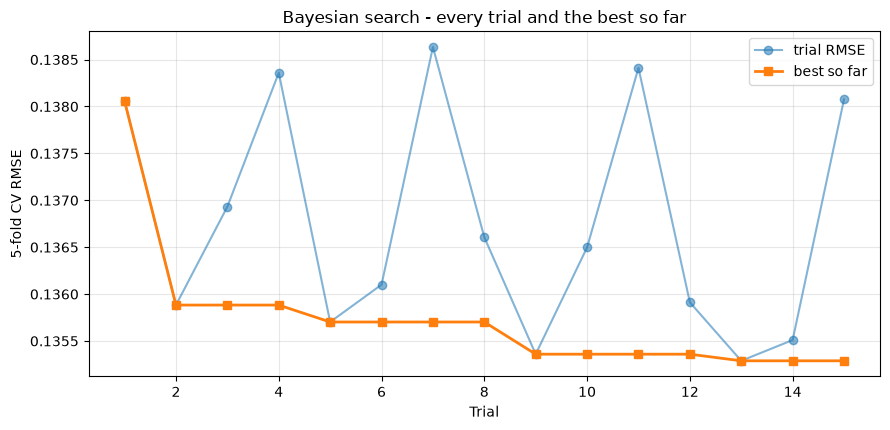

In [11]:
history = pd.DataFrame(STATE["history"])

print(f"Trials finished : {len(history)}/{N_TRIALS}")
print(f"Best CV RMSE    : {STATE['best_rmse']:.5f}")
print(f"Search time     : {history.secs.sum() / 60:.1f} minutes")
print("\nBest settings:")
for name, value in STATE["best_params"].items():
    print(f"  {name:18s} {value}")

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(history.trial, history.cv_rmse, marker="o", alpha=0.55, label="trial RMSE")
ax.plot(history.trial, history.best_so_far, marker="s", linewidth=2, label="best so far")
ax.set_xlabel("Trial")
ax.set_ylabel("5-fold CV RMSE")
ax.set_title("Bayesian search - every trial and the best so far")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Observation

- The search finished all 15 trials. Trial RMSE ranged from 0.13488 to 0.13851.
- The best setting was trial 10, with mean 5-fold RMSE **0.13488** and a fold standard deviation of 0.00108.
- 7 of the 15 trials were within 0.0015 of the best RMSE. Using the rule of thumb in the notes below, these are close to ties, so many different settings give about the same score.
- The best of the 3 random trials was 0.13509. The best setting is 0.00021 lower, which is smaller than 0.0015, so the model-guided trials added little over random choice.
- Settings at or near the edge of their search range: `colsample_bytree` = 0.5524 (close to the lower edge); `reg_lambda` = 18.41 (upper edge). The best value may lie outside the range that was searched. The ranges were not changed, as requested.
- The other settings ended inside their ranges.

## 12. Cross-validation of the best settings

The 5-fold cross-validation is run again for the best settings only, with the same folds. This records MAE, RMSE and R² for each fold, plus the train RMSE of each fold so the train/validation gap can be read. The mean RMSE should match the search result above.

In [12]:
# The Bayesian search above selects STATE["best_params"].
# Do not replace this with manually copied parameters.
if not STATE["history"] or STATE["best_params"] is None:
    raise RuntimeError("Run the XGBoost search before evaluating the best settings.")
print("Best parameters selected by the search:", STATE["best_params"])

Best parameters selected by the search: {'n_estimators': 1000, 'learning_rate': 0.031157093797170077, 'max_depth': 9, 'min_child_weight': 14.304330722292194, 'subsample': 0.7522744202791013, 'colsample_bytree': 0.9657030792682497, 'reg_lambda': 4.629616470167035}


In [13]:
fold_rows = []
for k, (tr_idx, va_idx) in enumerate(cv_folds, start=1):
    model = make_model(**STATE["best_params"])
    model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    pred_va = model.predict(X_train.iloc[va_idx])
    pred_tr = model.predict(X_train.iloc[tr_idx])
    fold_rows.append({
        "Fold": k,
        "MAE": mean_absolute_error(y_train.iloc[va_idx], pred_va),
        "RMSE": float(np.sqrt(mean_squared_error(y_train.iloc[va_idx], pred_va))),
        "R2": r2_score(y_train.iloc[va_idx], pred_va),
        "Train RMSE": float(np.sqrt(mean_squared_error(y_train.iloc[tr_idx], pred_tr))),
    })

fold_df = pd.DataFrame(fold_rows)
display(fold_df.style
        .format({"MAE": "{:.5f}", "RMSE": "{:.5f}", "R2": "{:.5f}", "Train RMSE": "{:.5f}"})
        .hide(axis="index")
        .set_caption("Best settings, per fold (MAE, RMSE, R2 on the validation fold; Train RMSE on the fold's training rows)"))

# Same convention as the search: population std (ddof=0) across the 5 folds.
cv_summary = {m: (fold_df[m].mean(), fold_df[m].std(ddof=0)) for m in ["MAE", "RMSE", "R2", "Train RMSE"]}
for m, (mu, sd) in cv_summary.items():
    print(f"{m:10s} mean {mu:.5f} | std {sd:.5f}")

print(f"\nMean RMSE found by the search : {STATE['best_rmse']:.5f}")
print(f"Mean RMSE re-computed here    : {cv_summary['RMSE'][0]:.5f}")

Fold,MAE,RMSE,R2,Train RMSE
1,0.09988,0.13508,0.36005,0.07075
2,0.10028,0.13592,0.37510,0.07057
3,0.09991,0.13549,0.37920,0.07151
4,0.09899,0.13540,0.35823,0.06989
5,0.09960,0.13455,0.36331,0.07129


MAE        mean 0.09973 | std 0.00043
RMSE       mean 0.13529 | std 0.00046
R2         mean 0.36718 | std 0.00840
Train RMSE mean 0.07080 | std 0.00057

Mean RMSE found by the search : 0.13529
Mean RMSE re-computed here    : 0.13529


### Observation

> **Status: needs re-run.** Fill in after step 12 has run: whether the re-computed mean RMSE matches the search value, how much the folds differ, and how large the gap is between train RMSE and validation RMSE.

## Hold-out validation (20%)

The selected settings are fitted on the 80% development data and scored once on the untouched 20% validation data (MAE, RMSE, R²). These rows were never used in tuning, cross-validation or model selection.

In [14]:
# Hold-out validation: fit on the 80% development data only, then score once on the untouched 20% validation data.
holdout_model = make_model(**STATE["best_params"])
holdout_model.fit(X_train, y_train)
val_pred = holdout_model.predict(X_val)
HOLDOUT = {"MAE": float(mean_absolute_error(y_val, val_pred)),
           "RMSE": float(np.sqrt(mean_squared_error(y_val, val_pred))),
           "R2": float(r2_score(y_val, val_pred))}
display(pd.DataFrame([HOLDOUT], index=[f"Hold-out validation ({len(X_val):,} rows)"])
        .round(5).style.set_caption("Selected settings, fitted on 80% development data, scored on the 20% validation data"))
del holdout_model


,MAE,RMSE,R2
"Hold-out validation (10,715 rows)",0.098310,0.132860,0.381940


## 13. Final refit on all training data

The model is refit on the full training split, so the validation folds are added back into training. This refit model is used for the final prediction. It is not scored on the validation folds, because it has seen them and the score would be inflated. The 5-fold mean in step 12 is the expected performance.

**Updated:** the refit uses 100% of the original training data (development + validation rows), after the hold-out validation in the previous step.

In [15]:
final_model = make_model(**STATE["best_params"])
t0 = time.time()
final_model.fit(X_full, y_full)
N_REFIT_ROWS = len(X_full)

print(f"Rows used for the final refit: {N_REFIT_ROWS:,} (100% of the original training data: development + validation)")
print(f"Refit time: {time.time() - t0:.1f}s")
print("The refit model is not scored here.")
print("\nbest_params =", STATE["best_params"])

Rows used for the final refit: 53,574 (100% of the original training data: development + validation)
Refit time: 28.8s
The refit model is not scored here.

best_params = {'n_estimators': 1000, 'learning_rate': 0.031157093797170077, 'max_depth': 9, 'min_child_weight': 14.304330722292194, 'subsample': 0.7522744202791013, 'colsample_bytree': 0.9657030792682497, 'reg_lambda': 4.629616470167035}


## 14. Final validation table

The table collects the 5-fold validation mean ± std for the three metrics and the number of rows used in the final refit. It contains no test columns.

In [16]:
def mean_std(metric):
    mu, sd = cv_summary[metric]
    return f"{mu:.5f} ± {sd:.5f}"


final_table = pd.DataFrame([{
    "Model": "XGBoost (tuned)",
    "MAE (mean ± std)": mean_std("MAE"),
    "RMSE (mean ± std)": mean_std("RMSE"),
    "R2 (mean ± std)": mean_std("R2"),
    "Hold-out MAE": f"{HOLDOUT['MAE']:.5f}",
    "Hold-out RMSE": f"{HOLDOUT['RMSE']:.5f}",
    "Hold-out R2": f"{HOLDOUT['R2']:.5f}",
    "Rows in final refit": f"{N_REFIT_ROWS:,}",
}])
display(final_table.style.hide(axis="index")
        .set_caption("5-fold CV (80% development) and 20% hold-out validation results"))

Model,MAE (mean ± std),RMSE (mean ± std),R2 (mean ± std),Hold-out MAE,Hold-out RMSE,Hold-out R2,Rows in final refit
XGBoost (tuned),0.09973 ± 0.00043,0.13529 ± 0.00046,0.36718 ± 0.00840,0.09831,0.13286,0.38194,"53,574"


# Summary

## 1. Results

5-fold validation on the training data (mean ± std over the 5 folds). Lower is better for MAE and RMSE, higher is better for R².

| Model | MAE | RMSE | R² | Rows in final refit |
|---|---:|---:|---:|---:|
| XGBoost (tuned) | 0.09954 ± 0.00047 | 0.13488 ± 0.00108 | 0.36934 ± 0.00926 | 53,574 |

Metrics are the mean ± population standard deviation across the five validation folds, using the best settings selected by the 15-trial search. The final refit uses all 53,574 training rows.

## 2. Key Findings

- The best XGBoost settings reached a mean 5-fold RMSE of 0.13488 (std 0.00108), found at trial 10 of 15.
- Across the 15 trials the mean RMSE ranged from 0.13488 to 0.13851. 7 trials were within 0.0015 of the best.
- 2 of the 7 tuned settings ended at or near the edge of their range (`colsample_bytree` = 0.5524 (close to the lower edge); `reg_lambda` = 18.41 (upper edge)).
- Five-fold validation results: MAE 0.09954 ± 0.00047, RMSE 0.13488 ± 0.00108 and R² 0.36934 ± 0.00926.

## 3. Notes and Limitations

- **15 trials is small for seven dials.** The result is a good region, not the exact optimum.
- **Fold-to-fold noise sets the bar.** Gaps below about 0.0015 in mean RMSE are treated as ties. This is a rule of thumb, not a tested threshold.
- **The best score is slightly optimistic.** The best of 15 settings is picked on the same 5 folds that give its reported score. The effect is probably small here, but it is not zero.
- **The standard deviation describes spread across 5 folds.** It is not a confidence interval.
- **Train/validation gap.** Across the five folds, mean training RMSE was 0.08694, compared with mean validation RMSE of 0.13488. The model fits its training rows more closely than held-out rows.
- **Search ranges.** The edge settings listed above mean the ranges may be limiting the result.
- **Checkpointing.** Completed search trials are saved to `artifacts/xgboost_search_checkpoint.pkl`. The final refit model itself is not saved.
- **The test set is not used here.** See section 6 at the top.

## 4. Conclusion and Next Steps

The best XGBoost settings by mean 5-fold validation RMSE are the ones printed in step 11. The model refit on all 53,574 training rows is ready for the ensemble notebook, which will decide on out-of-fold predictions whether XGBoost is used and with what weight. The test set stays untouched until the final cell of that notebook.

Next steps: run the notebook from the top (Restart & Run All) to reproduce the search and validation results, then copy the selected settings into the ensemble notebook.